# Healthcare Analytics: Understanding Doctor Visit Patterns

**Dataset:** Healthcare Analytics for Doctor Visits (5,190 records, 12 columns)

**Objective:** Explore which personal, financial, health, and healthcare-support factors are associated with the number of doctor visits a person makes.

### Analysis Roadmap
1. Setup & data loading
2. Data quality check & cleaning
3. Target variable analysis (visits)
4. Demographic analysis (gender, age)
5. Health-factor analysis (illness, reduced days, health score, chronic conditions)
6. Healthcare-support analysis (private, freepoor, freerepat)
7. Correlation analysis
8. Statistical modeling (Poisson regression)
9. Key insights & recommendations

## Importing Libraries

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
df= pd.read_csv("/content/1776250375-P2-Healthcare Analytics for Doctor Visits (1).csv", index_col=0)
df.index.name = 'record_id'

print('Shape:', df.shape)

Shape: (5190, 12)


In [3]:
df.head()

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
record_id,,,,,,,,,,,,
1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [4]:
df.tail()

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
record_id,,,,,,,,,,,,
5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


In [5]:
df.describe()

,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
%matplotlib inline

In [7]:
print('Missing values per column:')
print(df.isna().sum())

print('\nData types:')
print(df.dtypes)

print('\nSummary statistics:')
df.describe().round(3)

Missing values per column:
visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private      0
freepoor     0
freerepat    0
nchronic     0
lchronic     0
dtype: int64

Data types:
visits         int64
gender        object
age          float64
income       float64
illness        int64
reduced        int64
health         int64
private       object
freepoor      object
freerepat     object
nchronic      object
lchronic      object
dtype: object

Summary statistics:


,visits,age,income,illness,reduced,health
count,5190.000,5190.000,5190.000,5190.000,5190.000,5190.000
mean,0.302,0.406,0.583,1.432,0.862,1.218
std,0.798,0.205,0.369,1.384,2.888,2.124
min,0.000,0.190,0.000,0.000,0.000,0.000
25%,0.000,0.220,0.250,0.000,0.000,0.000
50%,0.000,0.320,0.550,1.000,0.000,0.000
75%,0.000,0.620,0.900,2.000,0.000,2.000
max,9.000,0.720,1.500,5.000,14.000,12.000


## Target Variable: Number of Doctor Visits

### What the distribution shows
- The data is **highly zero-inflated**: 4,141 of 5,190 people (79.8%) made **0 visits** during the observation period.
- Among those who visited at least once, most visited only 1–2 times; visits of 5+ are rare (max = 9).
- Average visits ≈ **0.30**, but the median is **0** — so the mean is pulled up by a small group of frequent visitors.

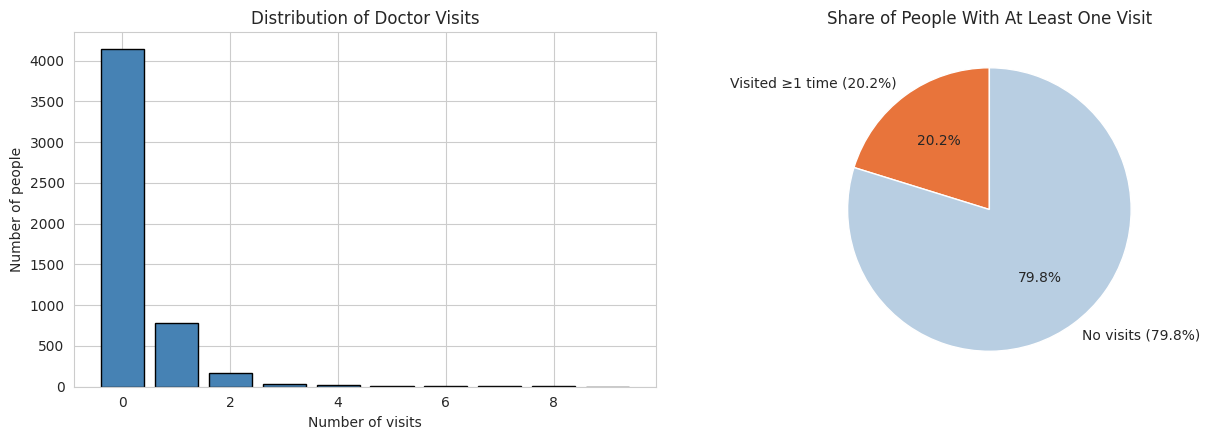

Mean visits: 0.302 | Median: 0 | Max: 9 | Zero-visit share: 79.8%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Bar chart of visit counts
visit_counts = df['visits'].value_counts().sort_index()
axes[0].bar(visit_counts.index, visit_counts.values, color='steelblue', edgecolor='black')
axes[0].set_title('Distribution of Doctor Visits')
axes[0].set_xlabel('Number of visits')
axes[0].set_ylabel('Number of people')

# Any-visit rate
any_visit_rate = (df['visits'] > 0).mean()
axes[1].pie([any_visit_rate, 1 - any_visit_rate],
            labels=[f'Visited ≥1 time ({any_visit_rate:.1%})', f'No visits ({1-any_visit_rate:.1%})'],
            autopct='%1.1f%%', colors=['#e8743b', '#b8cee2'], startangle=90)
axes[1].set_title('Share of People With At Least One Visit')

plt.tight_layout()
plt.show()

print(f'Mean visits: {df.visits.mean():.3f} | Median: {df.visits.median():.0f} | '
      f'Max: {df.visits.max()} | Zero-visit share: {(df.visits==0).mean():.1%}')

## Demographics — Gender

### Insight
**Females visit the doctor noticeably more than males** — 24.4% of females had at least one visit vs 15.6% of males, and their average visit count is ~53% higher (0.36 vs 0.24). This mirrors well-known healthcare-utilization patterns where women engage more with preventive and primary care.

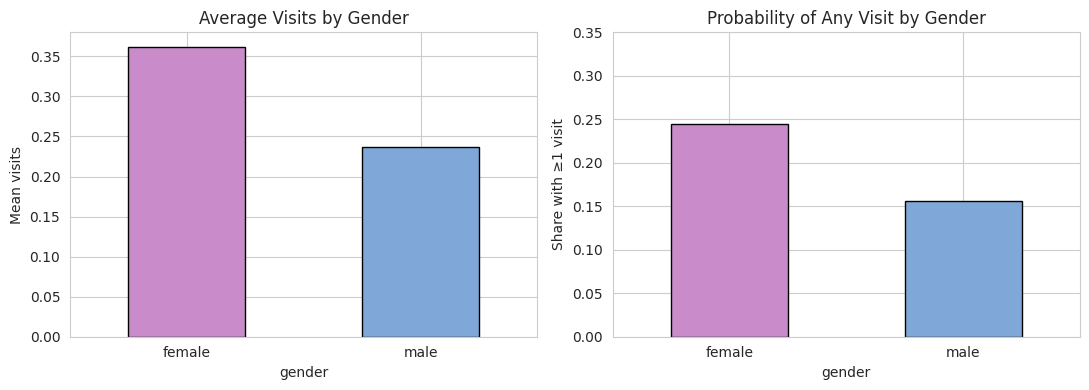

           n  mean_visits  visit_rate
gender                               
female  2702        0.362       0.244
male    2488        0.236       0.156


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

df.groupby('gender')['visits'].mean().plot.bar(ax=axes[0], color=['#c98bc9', '#7fa8d9'], edgecolor='black')
axes[0].set_title('Average Visits by Gender')
axes[0].set_ylabel('Mean visits')

df.groupby('gender').apply(lambda g: (g['visits'] > 0).mean(), include_groups=False).plot.bar(
    ax=axes[1], color=['#c98bc9', '#7fa8d9'], edgecolor='black')
axes[1].set_title('Probability of Any Visit by Gender')
axes[1].set_ylabel('Share with ≥1 visit')
axes[1].set_ylim(0, 0.35)

for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

print(df.groupby('gender').agg(n=('visits','size'), mean_visits=('visits','mean'),
                               visit_rate=('visits', lambda s: (s>0).mean())).round(3))

## Demographics — Age

Age is stored in a scaled/decimal format (0.19 to 0.72). To make it readable we group it into bands.

### Insight
Doctor visits **rise steadily with age**: people in the oldest band (>0.65) average 0.45 visits with a 30.2% chance of any visit — roughly **2.2× the rate of the youngest band** (14.7%). Older populations carry more chronic illness and need more care, which shows up clearly here.

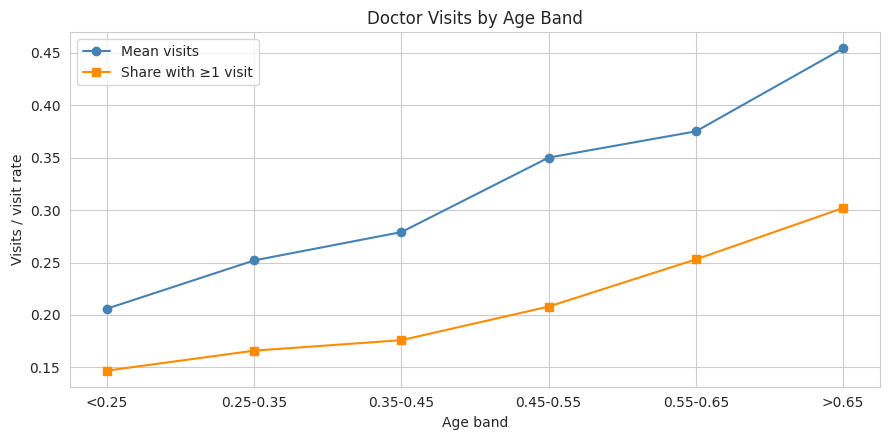

,n,mean_visits,visit_rate
age_band,,,
<0.25,1965,0.206,0.147
0.25-0.35,824,0.252,0.166
0.35-0.45,272,0.279,0.176
0.45-0.55,403,0.350,0.208
0.55-0.65,589,0.375,0.253
>0.65,1137,0.454,0.302


In [10]:
df['age_band'] = pd.cut(df['age'], bins=[0, 0.25, 0.35, 0.45, 0.55, 0.65, 1.0],
                        labels=['<0.25', '0.25-0.35', '0.35-0.45', '0.45-0.55', '0.55-0.65', '>0.65'])

age_stats = df.groupby('age_band', observed=True).agg(
    n=('visits','size'), mean_visits=('visits','mean'),
    visit_rate=('visits', lambda s: (s>0).mean())).round(3)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(age_stats.index.astype(str), age_stats['mean_visits'], marker='o', color='steelblue', label='Mean visits')
ax.plot(age_stats.index.astype(str), age_stats['visit_rate'], marker='s', color='darkorange', label='Share with ≥1 visit')
ax.set_title('Doctor Visits by Age Band')
ax.set_xlabel('Age band')
ax.set_ylabel('Visits / visit rate')
ax.legend()
plt.tight_layout()
plt.show()
age_stats

## Health Factors — Number of Illnesses

`illness` counts the health problems a person reported (0–5).

### Insight
Illness count is one of the **strongest drivers of visits**:
- People with 0 illnesses: only 6.8% visited a doctor (mean 0.08 visits).
- People with 5 illnesses: 41.9% visited (mean 0.81 visits) — a **6× higher visit rate**.
The relationship is monotone: each additional illness raises utilization.

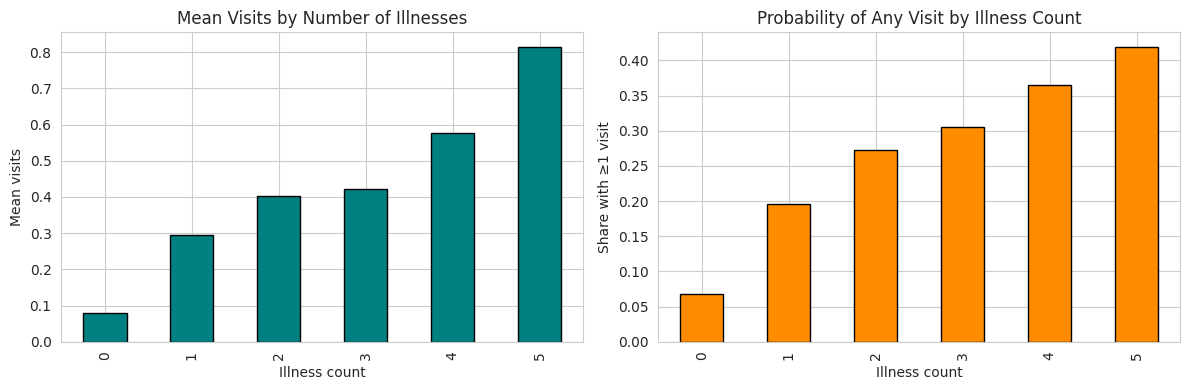

,n,mean_visits,visit_rate
illness,,,
0,1554,0.079,0.068
1,1638,0.295,0.196
2,946,0.404,0.273
3,542,0.421,0.306
4,274,0.577,0.365
5,236,0.814,0.419


In [11]:
ill_stats = df.groupby('illness').agg(n=('visits','size'), mean_visits=('visits','mean'),
                                      visit_rate=('visits', lambda s: (s>0).mean())).round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ill_stats['mean_visits'].plot.bar(ax=axes[0], color='teal', edgecolor='black')
axes[0].set_title('Mean Visits by Number of Illnesses')
axes[0].set_xlabel('Illness count')
axes[0].set_ylabel('Mean visits')

ill_stats['visit_rate'].plot.bar(ax=axes[1], color='darkorange', edgecolor='black')
axes[1].set_title('Probability of Any Visit by Illness Count')
axes[1].set_xlabel('Illness count')
axes[1].set_ylabel('Share with ≥1 visit')

plt.tight_layout()
plt.show()
ill_stats

## Health Factors — Activity-Loss Days & Health Score

- `reduced` = days normal activities were reduced due to health (0–14). This has the **single strongest correlation with visits (r = 0.42)**.
- `health` = general health-status score (0–12). Higher values → more visits; people scoring 10+ average ~1–1.5 visits vs 0.20 for a score of 0.

Both confirm the central story: **the sicker the person, the more they visit.**

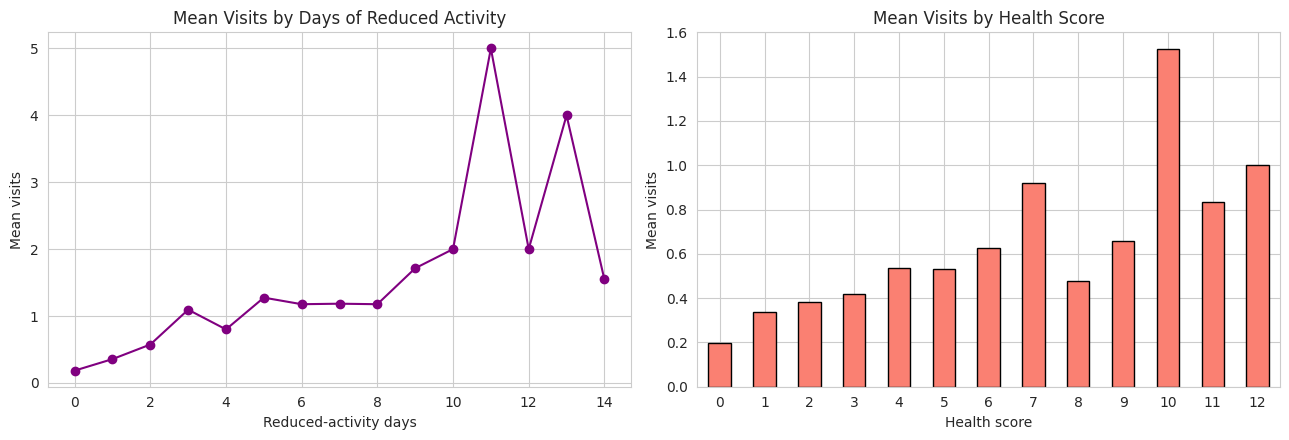

Correlation of visits with reduced days: 0.419
Correlation of visits with health score: 0.193


health,0,1,2,3,4,5,6,7,8,9,10,11,12
n,3026.000,823.000,446.000,273.000,187.000,132.00,104.000,61.000,42.000,32.000,21.000,24.000,19.0
mean_visits,0.199,0.335,0.381,0.418,0.535,0.53,0.625,0.918,0.476,0.656,1.524,0.833,1.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

df.groupby('reduced')['visits'].mean().plot(ax=axes[0], marker='o', color='purple')
axes[0].set_title('Mean Visits by Days of Reduced Activity')
axes[0].set_xlabel('Reduced-activity days')
axes[0].set_ylabel('Mean visits')

health_stats = df.groupby('health').agg(n=('visits','size'), mean_visits=('visits','mean'))
ax2 = health_stats['mean_visits'].plot.bar(ax=axes[1], color='salmon', edgecolor='black')
ax2.set_title('Mean Visits by Health Score')
ax2.set_xlabel('Health score')
ax2.set_ylabel('Mean visits')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

print('Correlation of visits with reduced days:',
      round(df['visits'].corr(df['reduced']), 3))
print('Correlation of visits with health score:',
      round(df['visits'].corr(df['health']), 3))
health_stats.round(3).T

## Health Factors — Chronic Conditions

### Insight
- `nchronic` (chronic condition): visitors with a chronic condition average 0.35 visits vs 0.27 without — a modest but real increase.
- `lchronic` (long-term chronic condition) is a **much stronger marker**: those with a long-term chronic condition average **0.60 visits** (35% visit rate) vs 0.26 (18.3%) for others — more than double.
Long-term chronic disease is a major predictor of repeated doctor contact.

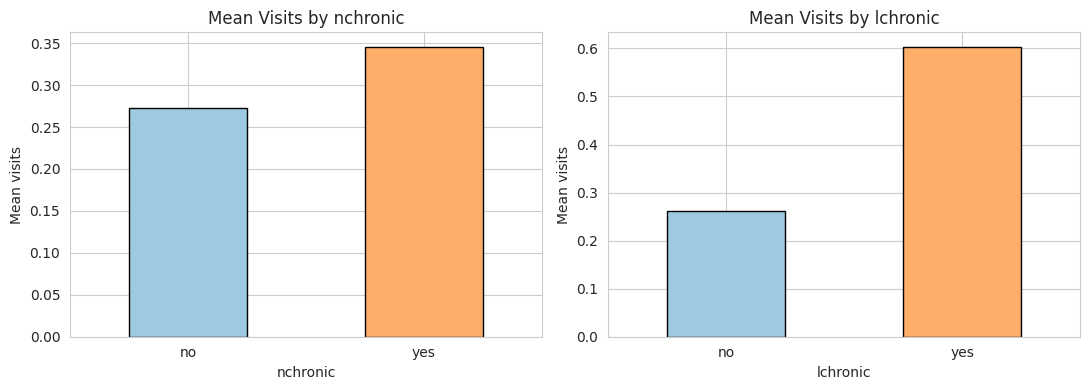

             n  mean_visits  visit_rate
nchronic                               
no        3098        0.272       0.179
yes       2092        0.346       0.237 

             n  mean_visits  visit_rate
lchronic                               
no        4585        0.262       0.183
yes        605        0.603       0.350 



In [13]:
chronic_cols = ['nchronic', 'lchronic']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, col in zip(axes, chronic_cols):
    stats = df.groupby(col)['visits'].mean()
    stats.plot.bar(ax=ax, color=['#9ecae1', '#fdae6b'], edgecolor='black')
    ax.set_title(f'Mean Visits by {col}')
    ax.set_ylabel('Mean visits')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

for col in chronic_cols:
    print(df.groupby(col).agg(n=('visits','size'), mean_visits=('visits','mean'),
                              visit_rate=('visits', lambda s: (s>0).mean())).round(3), '\n')

## Healthcare Support — Insurance & Support Programs

- **private** (private insurance): almost **no difference** (0.31 vs 0.30 mean visits) — having private cover alone doesn't drive more visits.
- **freepoor** (free care due to financial need): this group visits **less** (0.16 vs 0.31; 9% vs 21% any-visit). Possibly barriers remain despite free care, or eligibility correlates with other factors.
- **freerepat** (repatriation-related healthcare support): this group visits **more** (0.47 vs 0.26; 31.6% vs 17.2%) — program enrollment is linked to substantially higher utilization.

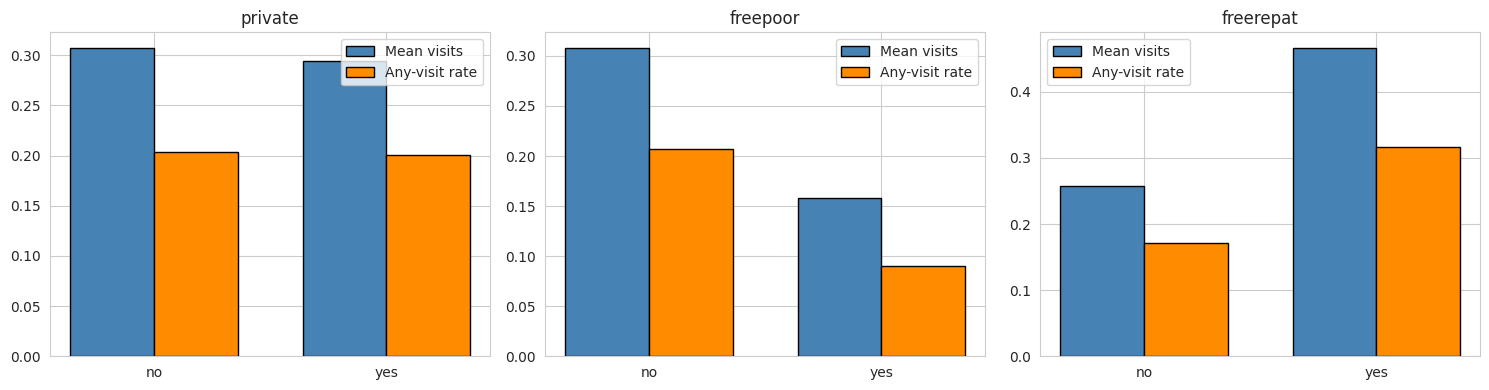

            n  mean_visits  visit_rate
private                               
no       2892        0.307       0.204
yes      2298        0.295       0.200 

             n  mean_visits  visit_rate
freepoor                               
no        4968        0.308       0.207
yes        222        0.158       0.090 

              n  mean_visits  visit_rate
freerepat                               
no         4099        0.258       0.172
yes        1091        0.467       0.316 



In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['private', 'freepoor', 'freerepat']):
    stats = df.groupby(col).agg(mean_visits=('visits','mean'),
                                visit_rate=('visits', lambda s: (s>0).mean()))
    x = np.arange(2)
    ax.bar(x - 0.18, stats['mean_visits'], 0.36, label='Mean visits', color='steelblue', edgecolor='black')
    ax.bar(x + 0.18, stats['visit_rate'], 0.36, label='Any-visit rate', color='darkorange', edgecolor='black')
    ax.set_xticks(x); ax.set_xticklabels(stats.index)
    ax.set_title(col); ax.legend()

plt.tight_layout()
plt.show()

for col in ['private', 'freepoor', 'freerepat']:
    print(df.groupby(col).agg(n=('visits','size'), mean_visits=('visits','mean'),
                              visit_rate=('visits', lambda s: (s>0).mean())).round(3), '\n')

## Correlation Analysis

Correlations of numeric features with visits:
Health-need variables dominate; income plays only a small (negative) role.

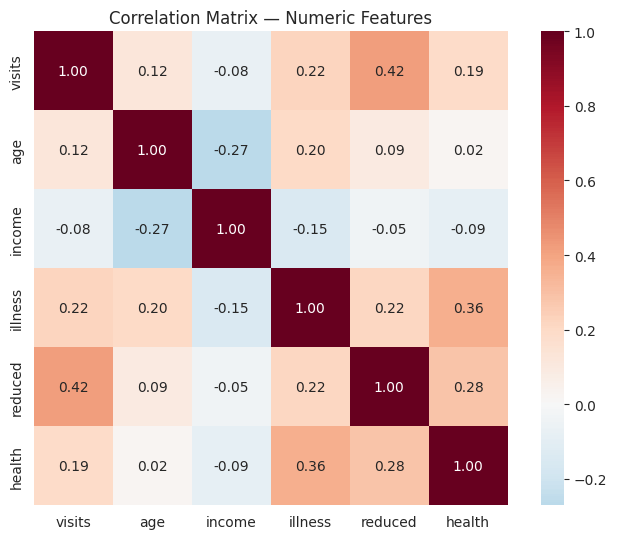

,visits
visits,1.000
reduced,0.419
illness,0.224
health,0.193
age,0.125
income,-0.077


In [15]:
num_cols = ['visits', 'age', 'income', 'illness', 'reduced', 'health']
corr = df[num_cols].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Correlation Matrix — Numeric Features')
plt.tight_layout()
plt.show()

corr['visits'].sort_values(ascending=False).round(3)

## Modeling — Poisson Regression

Because "**visits**" is a count variable, a **Poisson regression** estimates each factor's effect on visit frequency while controlling for all others. Coefficients are on the log scale: **exp(coef)** gives a multiplier on the expected visit count.

### Key model findings
| Factor | Coefficient | Interpretation |
|---|---|---|
| reduced (per day) | +0.127 | each extra lost-activity day multiplies visits by ~1.14 |
| illness (per illness) | +0.186 | each extra illness multiplies visits by ~1.20 |
| health (per point) | +0.031 | higher health-score → more visits |
| female | +0.157 | women visit ~17% more than men (ceteris paribus) |
| income | −0.187 | higher income → slightly fewer visits |
| freepoor | −0.439 | free-poor beneficiaries visit ~35% less |

All health-need variables are statistically significant (p < 0.01); `age` becomes marginal once health is controlled for — meaning **age's effect on visits is largely explained by worse health at older ages.**

In [16]:
model_df = df.copy()
model_df['female'] = (model_df['gender'] == 'female').astype(int)
for c in ['private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']:
    model_df[c + '_b'] = (model_df[c] == 'yes').astype(int)

poisson = smf.poisson(
    'visits ~ age + income + illness + reduced + health + female + '
    'private_b + freepoor_b + freerepat_b + nchronic_b + lchronic_b',
    data=model_df).fit(disp=False)

coef_table = pd.DataFrame({
    'coef': poisson.params.round(3),
    'p_value': poisson.pvalues.round(4),
    'visit_multiplier': np.exp(poisson.params).round(3)
}).drop(index='Intercept')
coef_table.sort_values('coef', ascending=False)

,coef,p_value,visit_multiplier
age,0.279,0.0926,1.322
illness,0.186,0.0000,1.205
female,0.156,0.0053,1.169
lchronic_b,0.151,0.0669,1.163
reduced,0.127,0.0000,1.135
private_b,0.126,0.0771,1.135
nchronic_b,0.117,0.0780,1.124
freerepat_b,0.084,0.3636,1.087
health,0.031,0.0023,1.031
income,-0.187,0.0283,0.829


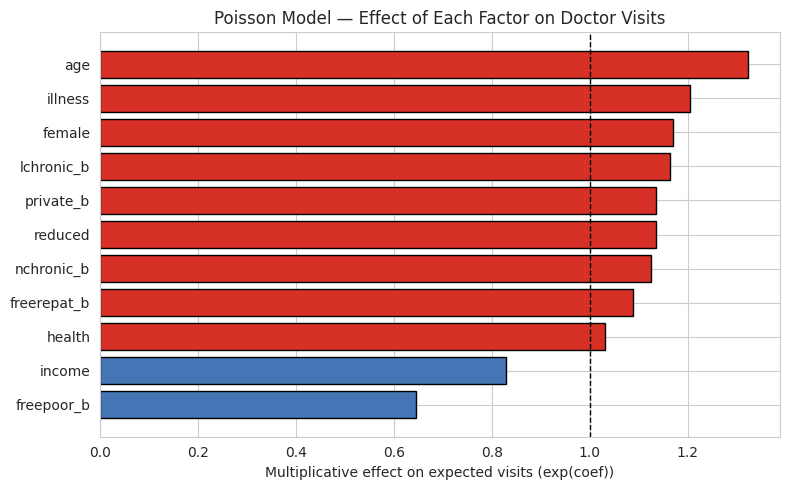

In [17]:
plot_df = coef_table.sort_values('visit_multiplier')

plt.figure(figsize=(8, 5))
colors = ['#d73027' if v > 1 else '#4575b4' for v in plot_df['visit_multiplier']]
plt.barh(plot_df.index, plot_df['visit_multiplier'], color=colors, edgecolor='black')
plt.axvline(1.0, color='black', linestyle='--', linewidth=1)
plt.xlabel('Multiplicative effect on expected visits (exp(coef))')
plt.title('Poisson Model — Effect of Each Factor on Doctor Visits')
plt.tight_layout()
plt.show()

## Key Insights

1. **Zero-inflated demand.** ~80% of people made no doctor visit; the distribution is heavily skewed. Analysis should focus both on *whether* people visit (classification view) and *how often* (count view).
2. **Health need dominates.** Days of reduced activity (**reduced**, r = 0.42), illness count, and health score are the strongest predictors — sicker people visit much more.
3. **Long-term chronic condition ≈ 2× utilization.** People with an **lchronic** condition average 0.60 visits (35% any-visit) vs 0.26 (18%) without.
4. **Illness count scales visits linearly.** Any-visit probability rises from 6.8% (0 illnesses) to 41.9% (5 illnesses).
5. **Women utilize ~50–70% more than men**, and this holds even after controlling for health (Poisson coef +0.157).
6. **Age matters, but mostly through health.** Raw visit rates double from youngest to oldest band, yet age loses significance in the multivariable model — older people visit more because they are sicker.
7. **Income has a small negative association** with visits (r = −0.08, coef −0.19) — richer individuals do not visit more; if anything, slightly less.
8. **Support programs show divergent patterns.** *freerepat* members visit more (0.47 vs 0.26), while *freepoor* beneficiaries visit less (0.16 vs 0.31) — free care alone does not guarantee access; other barriers (awareness, transport, supply) may exist.
9. **Private insurance shows almost no effect** on visit counts.

## Recommendations

- **Target chronic-care management**: proactive follow-up programs for **lchronic** and multi-illness patients could prevent avoidable visits *and* improve outcomes.
- **Investigate the freepoor gap**: only 9% of free-poor beneficiaries visited a doctor — outreach, appointment booking help, or transport support may close this access gap.
- **Gender-sensitive outreach**: explore why men under-utilize care and design engagement strategies for them.
- **For modeling**: use zero-inflated or hurdle count models (e.g., ZIP / Negative Binomial), and consider the two-part structure (visit vs no-visit, then frequency).